# Ergebnis-Plot: FT-iQPE auf dem Steane-Code

Dieses Notebook lädt die Ergebnisse und erzeugt den Vergleichsplot, den man frei anpassen kann.

**Datenquellen** (relativ zu diesem Ordner):

| Kurve | Datei | Erzeugt von |
|---|---|---|
| vollständiges iQPE, Steane und nackt | `results/full_*.json`, `results/bare_*.json` (Rohdaten pro Chunk) | `sweep.py` (lokal + HPC) |
| Ramsey-iQPE, Steane und nackt (Qiskit) | `../phase4_qiskit_hpc/results/sweep.json` | `plot_sweep.py` |
| Ramsey-iQPE, Steane (`fullsim.py`, Z als Frame) | `../phase3_endtoend/results/fullsim_summary.json` | `plot_fullsim.py` |

**Ablauf:**

1. Abschnitt 1 lädt die Daten. Beim vollständigen iQPE wird direkt aus den Rohdateien aggregiert, deshalb lässt sich die Winkelauswahl ändern.
2. Abschnitt 2 enthält **alle Stil-Einstellungen**. Normalerweise muss man nur dort etwas ändern.
3. Abschnitt 3 zeichnet und speichert den Plot.
4. Abschnitt 4 enthält optionale Zusatzplots: Vorteilsfaktor und Werte pro Winkel.

Fehlerbalken: Poisson-Fehler in der Zahl der falschen Schätzungen, also Mittelwert/√n.

In [8]:
import json
from collections import defaultdict
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

HERE = Path.cwd()          # Notebook im Ordner phase5_full_iqpe starten
assert (HERE / "results").is_dir(), "Bitte das Notebook im Ordner phase5_full_iqpe öffnen"

plt.rcParams.update({
    "text.usetex": True,
    "font.family": "serif"
})

## 1. Daten laden

In [22]:
def aggregate_full(angles=(2, 4, 6)):
    # Vollständiges iQPE aus den Rohdateien: Mittel über die gewählten Winkel.
    # Rückgabe: {"full": [...], "bare": [...]}, je Liste von dicts (p, mean, err, shots, n_wrong, ...).
    agg = defaultdict(lambda: defaultdict(lambda: [0, 0.0, 0, 0]))
    for f in list((HERE / "results").glob("full_*.json")) + list((HERE / "results").glob("bare_*.json")):
        r = json.load(open(f))
        if r["j"] not in angles:
            continue
        a = agg[(r["run"], r["p"])][r["j"]]
        a[0] += r["shots"]; a[1] += r["sum_dphi"]; a[2] += r["n_wrong"]; a[3] += r.get("system_flipped") or 0
    out = {"full": [], "bare": []}
    for (run, p), per in agg.items():
        means = [v[1] / v[0] for v in per.values()]
        nw = sum(v[2] for v in per.values())
        mean = float(np.mean(means))
        out[run].append(dict(p=p, mean=mean, err=mean / np.sqrt(max(nw, 1)), n_wrong=nw,
                             shots=sum(v[0] for v in per.values()), angles=sorted(per),
                             s_flip=sum(v[3] for v in per.values()) / sum(v[0] for v in per.values()),
                             per_angle={j: v[1] / v[0] for j, v in sorted(per.items())}))
    for k in out:
        out[k].sort(key=lambda r: r["p"])
    return out


def load_ramsey_qiskit():
    rows = json.load(open(HERE.parent / "phase4_qiskit_hpc" / "results" / "sweep.json"))
    out = {"steane": [], "bare": []}
    for r in rows:
        if r.get("eps") is None:
            out[r["code"]].append(dict(p=r["p"], mean=r["mean_dphi"], err=r["err"], shots=r["shots"]))
    for k in out:
        out[k].sort(key=lambda r: r["p"])
    return out


def load_ramsey_fullsim():
    rows = json.load(open(HERE.parent / "phase3_endtoend" / "results" / "fullsim_summary.json"))["fullsim"]
    return sorted((dict(p=r["p"], mean=r["mean_dphi"], err=r["err"], shots=r["shots"]) for r in rows),
                  key=lambda r: r["p"])


ANGLES = (2, 4, 6)          # Winkel j/8 für das vollständige iQPE (nur gerade j sind exakt gerechnet)
full = aggregate_full(ANGLES)
ramsey = load_ramsey_qiskit()
ramsey_fs = load_ramsey_fullsim()

DATA = {                    # Schlüssel -> Liste von Punkten; diese Schlüssel verwendet STYLE unten
    "full_steane": full["full"],
    "full_bare": full["bare"],
    "ramsey_steane": ramsey["steane"],
    "ramsey_bare": ramsey["bare"],
}

print(f"{'Datensatz':16s} {'p':>8s} {'Δφ':>10s} {'± ':>9s} {'Shots':>9s}")
for key, rows in DATA.items():
    for r in rows:
        print(f"{key:16s} {r['p']:8.1e} {r['mean']:10.3e} {r['err']:9.1e} {r['shots']:9d}")

Datensatz               p         Δφ        ±      Shots
full_steane       1.0e-04  9.133e-05   5.5e-06   1142784
full_steane       2.0e-04  3.278e-04   1.3e-05    761856
full_steane       5.0e-04  2.009e-03   4.5e-05    384512
full_steane       1.0e-03  7.824e-03   1.7e-04     98304
full_steane       2.0e-03  2.908e-02   4.8e-04     49152
full_steane       5.0e-03  1.262e-01   1.4e-03     24576
full_bare         1.0e-04  5.877e-04   5.8e-06   6000000
full_bare         2.0e-04  1.179e-03   8.2e-06   6000000
full_bare         5.0e-04  2.925e-03   1.3e-05   6000000
full_bare         1.0e-03  5.820e-03   1.8e-05   6000000
full_bare         2.0e-03  1.152e-02   2.6e-05   6000000
full_bare         5.0e-03  2.773e-02   4.0e-05   6000000
ramsey_steane     5.0e-04  1.275e-03   4.6e-05    224000
ramsey_steane     1.0e-03  4.290e-03   1.1e-04    112000
ramsey_steane     2.0e-03  1.422e-02   2.9e-04     56000
ramsey_steane     5.0e-03  7.161e-02   9.5e-04     28000
ramsey_bare       5.0e-04  2.13

## 2. Stil-Einstellungen

Hier ist alles einstellbar: welche Kurven, Beschriftungen, Farben, Marker, Achsen, Schrift, Break-even-Linien und Export.

- Kurven ein- und ausschalten mit `show`.
- Die Reihenfolge der Einträge in `STYLE` ist die Reihenfolge in der Legende.

In [29]:
STYLE = {
    "full_steane":    dict(show=True,  label="iQPE Steane", color="#0d366b",
                           marker="D", ls="-",  lw=2.0, ms=6.5),
    "full_bare":      dict(show=True,  label="iQPE physical",            color="#8a8984",
                           marker="o", ls=":",  lw=2.0, ms=6.5),
    "ramsey_steane":  dict(show=True,  label="Ramsey iQPE Steane",        color="#6b8fc4",
                           marker="s", ls="--", lw=2.0, ms=5.0),
    "ramsey_bare":    dict(show=True,  label="Ramsey iQPE physical",    color="#b9b8b3",
                           marker="s", ls=":",  lw=2.0, ms=5.0),
    "ramsey_fullsim": dict(show=False, label="Ramsey iQPE, Steane (fullsim, Z as frame)", color="#9c6ade",
                           marker="^", ls="--", lw=1.5, ms=5.0),
}

# Break-even-Linien: (logische Kurve, nackte Kurve, Farbe, Beschriftung oder None)
BREAKEVEN = [
    ("full_steane",   "full_bare",   "#0d366b", "break-even full iQPE"),
    ("ramsey_steane", "ramsey_bare", "#6b8fc4", "break-even Ramsey"),
]
SHOW_BREAKEVEN = True
BREAKEVEN_IN_LEGEND = False       # True: Linien in der Legende; False: Text am oberen Rand
SHOW_ERRORBARS = True

FIG = dict(
    figsize=(6.8, 5.0),
    title="FT iQPE on the Steane code with real T gates",
    title_size=11,
    xlabel="physical error rate $p$",
    ylabel=r"mean phase error $\Delta\varphi$",
    xlim=None,                    # z.B. (8e-5, 6e-3)
    ylim=None,                    # z.B. (5e-5, 2e-1)
    font_size=10,
    legend_loc="upper left",
    legend_size=8,
    grid=True,
    caption=("3 iterations; full iQPE: angles $j/8$, $j = 2, 4, 6$, ancilla + system block, "
             "controlled-Z / controlled-S with teleported T gates;\nRamsey: one block, $j = 1, \\dots, 7$. "
             "SD6 circuit noise on every gate, reset and measurement, no idle noise."),
    caption_size=7,
)

EXPORT = dict(
    basename="results/compare_notebook",   # ohne Endung
    formats=("png", "pdf"),                 # z.B. ("pdf",) für LaTeX
    dpi=200,
)

## 3. Plot

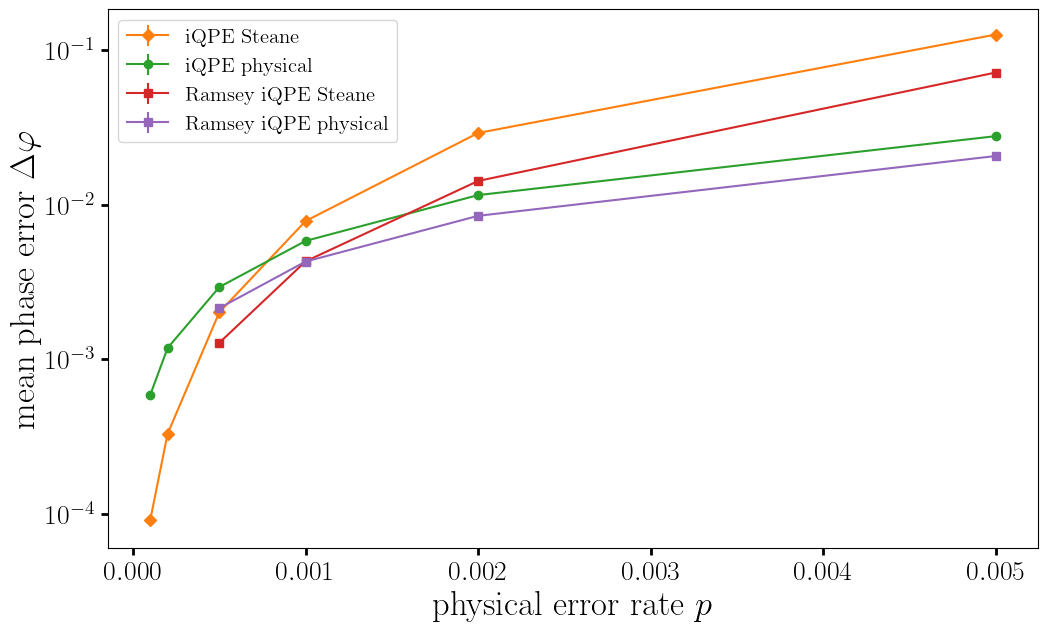

In [54]:
color=['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd','#7f7f7f','#17becf', '#8c564b', '#e377c2', '#bcbd22', ]

fig, ax = plt.subplots(figsize=(12,7)) #erzeugt plot umgebung

style_dict={'fmt': 'x-',
     'markersize': 10,
     'linewidth': 2}

counter=0
for key, st in STYLE.items():
     counter=counter+1
     if counter <5:
          rows = DATA.get(key, [])
          x = [r["p"] for r in rows]; y = [r["mean"] for r in rows]
          yerr = [r["err"] for r in rows] if SHOW_ERRORBARS else None
          ax.errorbar(x, y, yerr=yerr, label=st["label"], color=color[counter], marker=st["marker"])


ax.set_ylabel(r'mean phase error $\Delta \varphi$',fontsize=25) #name der X-Achse

ax.set_xlabel(r'physical error rate $p$',fontsize=25) #name der Y-Achse
ax.legend( prop={'size': 15})
#ax.set_xlim((5,90)) #X-Bereich
#ax.set_ylim((-1,50)) #Y-Bereich

#plt.title('Combined Plot'.format(layer),fontsize=35)

plt.minorticks_on() #erzeugt auch kleine ticks zwischen den großen
ax.tick_params(axis='both',which='major', length=5, width=2, labelsize=20)
ax.tick_params(axis='both',which='minor', length=0, width=2, labelsize=20)
plt.autoscale()
ax.set_yscale('log')
#ax.set_xscale('log')
plt.show() #erzeugt plot

fig.savefig('crossover.pdf' , bbox_inches="tight") #speichert plot als pdf ohne viel weißen rand

#print('Optimal Sigma: ', np.min(full.sigma[full.iter==99][full.cost==np.min(full.cost[full.iter==99])])/np.pi)

## 4. Zusatzplots (optional)

**4a. Vorteilsfaktor:** Δφ(Steane) / Δφ(nackt). Werte unter 1 heißen, die Codierung gewinnt.

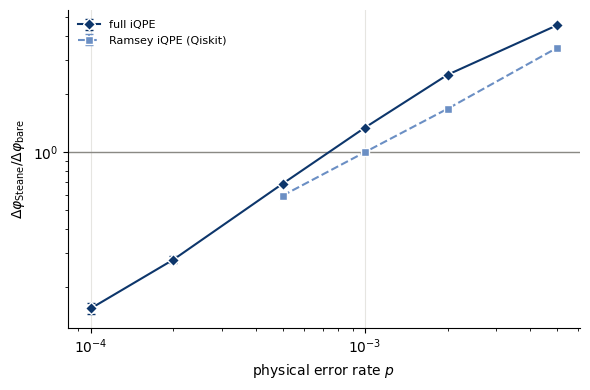

In [5]:
fig2, ax2 = plt.subplots(figsize=(6.0, 4.0))
for lk, bk in (("full_steane", "full_bare"), ("ramsey_steane", "ramsey_bare")):
    b = {r["p"]: r for r in DATA[bk]}
    pts = [(r["p"], r["mean"] / b[r["p"]]["mean"],
            r["mean"] / b[r["p"]]["mean"] * np.hypot(r["err"] / r["mean"], b[r["p"]]["err"] / b[r["p"]]["mean"]))
           for r in DATA[lk] if r["p"] in b]
    if pts:
        x, y, e = zip(*pts)
        ax2.errorbar(x, y, yerr=e, color=STYLE[lk]["color"], marker=STYLE[lk]["marker"], ls=STYLE[lk]["ls"],
                     mec="white", capsize=3, label=STYLE[lk]["label"].replace(", Steane", "").replace(", 2 Steane logical qubits", ""))
ax2.axhline(1, color="#8a8984", lw=1)
ax2.set_xscale("log"); ax2.set_yscale("log")
ax2.set_xlabel(FIG["xlabel"]); ax2.set_ylabel(r"$\Delta\varphi_\mathrm{Steane} / \Delta\varphi_\mathrm{bare}$")
ax2.grid(True, color="#e6e5e1"); ax2.legend(fontsize=8, frameon=False)
for s in ("top", "right"):
    ax2.spines[s].set_visible(False)
fig2.tight_layout()
plt.show()

**4b. Vollständiges iQPE pro Winkel:** j = 4 hat nur ein CZ, j = 2 ein CS, j = 6 ein CS³ mit 4 T-Gadgets.

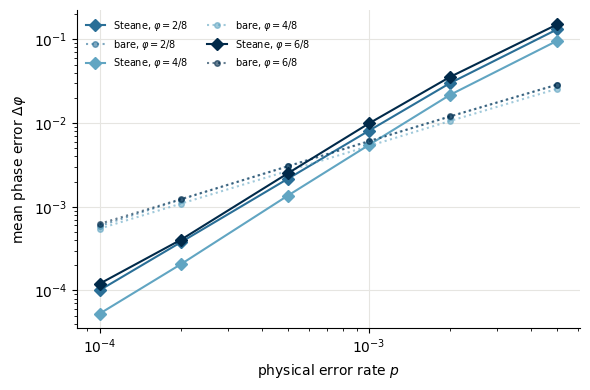

In [6]:
fig3, ax3 = plt.subplots(figsize=(6.0, 4.0))
cols = {2: "#2a6f97", 4: "#61a5c2", 6: "#012a4a"}
for j in ANGLES:
    rows = [r for r in DATA["full_steane"] if j in r["per_angle"]]
    ax3.plot([r["p"] for r in rows], [r["per_angle"][j] for r in rows], marker="D", color=cols.get(j),
             label=f"Steane, $\\varphi = {j}/8$")
    rows = [r for r in DATA["full_bare"] if j in r["per_angle"]]
    ax3.plot([r["p"] for r in rows], [r["per_angle"][j] for r in rows], ls=":", marker="o", ms=4,
             color=cols.get(j), alpha=0.6, label=f"bare, $\\varphi = {j}/8$")
ax3.set_xscale("log"); ax3.set_yscale("log")
ax3.set_xlabel(FIG["xlabel"]); ax3.set_ylabel(FIG["ylabel"])
ax3.grid(True, color="#e6e5e1"); ax3.legend(fontsize=7, frameon=False, ncol=2)
for s in ("top", "right"):
    ax3.spines[s].set_visible(False)
fig3.tight_layout()
plt.show()

**4c. Logischer Kippanteil des System-Blocks** (vollständiges iQPE, am Ende in Z gemessen)

In [ ]:
for r in DATA["full_steane"]:
    print(f"p = {r['p']:.0e}:  S gekippt in {r['s_flip']:.2e} der Shots   ({r['shots']} Shots)")